In [2]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MinMaxScaler
from sklearn.naive_bayes import BernoulliNB, MultinomialNB, GaussianNB
from sklearn.metrics import accuracy_score, classification_report, ConfusionMatrixDisplay

CSV_PATH = Path("heart attack analysis.csv")
df = pd.read_csv(CSV_PATH)
X = df.drop(columns="output")
y = df["output"].astype(int)
print("Shape:", df.shape)
print("Missing values:", int(df.isna().sum().sum()))
print("Target counts:\n", y.value_counts().sort_index())
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=42, stratify=y
)

Shape: (303, 14)
Missing values: 0
Target counts:
 output
0    138
1    165
Name: count, dtype: int64


## Bernoulli Naive Bayes

Convert each predictor to 0/1 using the training-set median threshold. The training medians are reused for the holdout set.

In [3]:
medians = X_train.median()
X_train_bernoulli = (X_train > medians).astype(int)
X_test_bernoulli = (X_test > medians).astype(int)
bernoulli_model = BernoulliNB()
bernoulli_model.fit(X_train_bernoulli, y_train)
bernoulli_pred = bernoulli_model.predict(X_test_bernoulli)
print("BernoulliNB accuracy:", accuracy_score(y_test, bernoulli_pred))
print(classification_report(y_test, bernoulli_pred, zero_division=0))

BernoulliNB accuracy: 0.7763157894736842
              precision    recall  f1-score   support

           0       0.82      0.66      0.73        35
           1       0.75      0.88      0.81        41

    accuracy                           0.78        76
   macro avg       0.79      0.77      0.77        76
weighted avg       0.78      0.78      0.77        76



## Multinomial Naive Bayes

Min-max scaling ensures all values are nonnegative. The scaler is fitted on training data only.

In [4]:
minmax = MinMaxScaler()
X_train_multi = minmax.fit_transform(X_train)
X_test_multi = minmax.transform(X_test)
multinomial_model = MultinomialNB()
multinomial_model.fit(X_train_multi, y_train)
multinomial_pred = multinomial_model.predict(X_test_multi)
print("MultinomialNB accuracy:", accuracy_score(y_test, multinomial_pred))
print(classification_report(y_test, multinomial_pred, zero_division=0))

MultinomialNB accuracy: 0.7368421052631579
              precision    recall  f1-score   support

           0       0.78      0.60      0.68        35
           1       0.71      0.85      0.78        41

    accuracy                           0.74        76
   macro avg       0.75      0.73      0.73        76
weighted avg       0.74      0.74      0.73        76



## Gaussian Naive Bayes and comparison

GaussianNB accuracy: 0.7763157894736842
              precision    recall  f1-score   support

           0       0.80      0.69      0.74        35
           1       0.76      0.85      0.80        41

    accuracy                           0.78        76
   macro avg       0.78      0.77      0.77        76
weighted avg       0.78      0.78      0.77        76



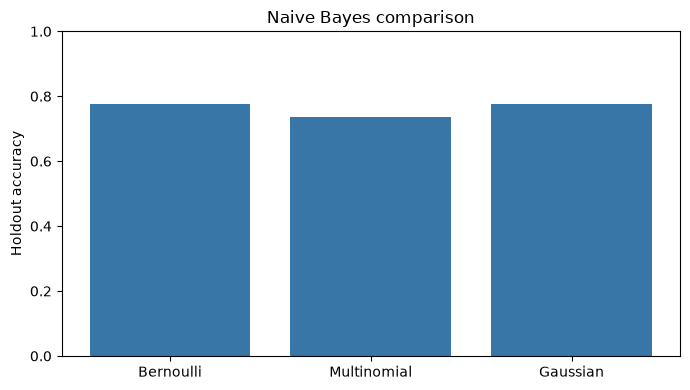

In [5]:
gaussian_model = GaussianNB()
gaussian_model.fit(X_train, y_train)
gaussian_pred = gaussian_model.predict(X_test)
print("GaussianNB accuracy:", accuracy_score(y_test, gaussian_pred))
print(classification_report(y_test, gaussian_pred, zero_division=0))

models = {
    "Bernoulli": (bernoulli_model, X_test_bernoulli),
    "Multinomial": (multinomial_model, X_test_multi),
    "Gaussian": (gaussian_model, X_test),
}
accuracies = {name: accuracy_score(y_test, model.predict(features))
              for name, (model, features) in models.items()}
plt.figure(figsize=(7, 4))
plt.bar(accuracies.keys(), accuracies.values(), color="#3976a8")
plt.ylim(0, 1); plt.ylabel("Holdout accuracy"); plt.title("Naive Bayes comparison")
plt.tight_layout(); plt.show()